# Predicting focal spots and rays with HelioBeamAI

This tutorial shows how to

1. get the released model files,
2. predict focal spots of heliostats from their calibration measurements and compare them with
   measurements the model has not seen,
3. predict spots for new sun positions and aim points,
4. turn spots into rays (projection CNN) and the flux on a plane, including a Gaussian fallback for
   heliostats without calibration data.

It uses the example data in `examples/data/` (5 heliostats of the Jülich solar tower, see
`02_example_data.ipynb`) and runs on a CPU in about a minute.

**Coordinates.** Tower-base frame in metres: x east, y north, z up. `sun` is the unit vector towards
the sun. Focal spot images are 64 x 64 pixels on 6 m x 6 m around the aim point in the vertical plane
facing north (+y), in *frame C*: row 0 at the top, column 0 at the east edge, so `plt.imshow` shows the
spot as seen from the field (east left).

In [1]:
from pathlib import Path
import math
import torch
import matplotlib.pyplot as plt

from heliobeamai import (FluxPredictor, GaussianSource, HelioBeamField, artifacts, build_conditions,
                         normalize_heliostat_id)
from heliobeamai.data import get_split
from heliobeamai.training.losses import relative_flux_deviation

torch.manual_seed(0)
DATA = Path("data")                          # examples/data
artifacts.download("prediction")             # ~30 MB once; afterwards only the checksum is checked
print(artifacts.verify("prediction"))        # files in artifacts.root()

{'transformer/T2026.pt': 'ok', 'encoder_cache/T2026.pt': 'ok', 'projector/cnn_frameC_v1.pt': 'ok'}


## 1. Calibration measurements of a heliostat

`calibration_2026.pt` has the format of the training dataset: for every heliostat 45 measured flux
images (`imgs`) and their conditions (`data`: sun vector, aim direction, aim distance in m).

In [2]:
data = torch.load(DATA / "calibration_2026.pt", weights_only=False)
ids = [normalize_heliostat_id(int(h)) for h in data["heliostat_ids"]]
imgs, cond = data["imgs"].float(), data["data"].float()       # [5, 45, 64, 64], [5, 45, 7]
print(ids, tuple(imgs.shape), tuple(cond.shape))

['AC26', 'AA44', 'AO50', 'AY27', 'BC71'] (5, 45, 64, 64) (5, 45, 7)


## 2. Context from measurements, prediction for held-out measurements

The transformer encoder reads a heliostat's measurements (its *context*); the decoder predicts the
spot for new conditions. The released encoder cache holds the context of all 1988 heliostats of the
2026 dataset. Here we build the context ourselves from the training samples only, exactly as for a
new heliostat, and predict the held-out test samples of the `T2026` split (the first 5 samples of
each target block; the model has not seen them in training).

Conditions for the model are `(sun, aim direction, distance / 350 m)`.

In [3]:
root = artifacts.root()
predictor = FluxPredictor.from_checkpoint(root / "transformer/T2026.pt")   # no encoder cache
train_idx, _ = get_split("T2026").indices(imgs.shape[1])
test_idx = torch.tensor([0, 1, 2, 3, 4, 15, 16, 17, 18, 19, 30, 31, 32, 33, 34])
for i, h in enumerate(ids):
    predictor.encode_context(h, imgs[i, train_idx], cond[i, train_idx])  # images [S,64,64], conditions [S,7] (m)

test_cond = cond[:, test_idx].clone()
test_cond[..., 6] /= 350.0                                                 # model conditions
pred = predictor.predict(ids, test_cond)                                   # [5, 15, 64, 64]
meas = imgs[:, test_idx]
err = relative_flux_deviation(meas, pred)
for h, e in zip(ids, err):
    print(f"{h}: relative flux deviation {e.mean():.3f} (mean of {len(e)} held-out images)")

AC26: relative flux deviation 0.113 (mean of 15 held-out images)
AA44: relative flux deviation 0.148 (mean of 15 held-out images)
AO50: relative flux deviation 0.137 (mean of 15 held-out images)
AY27: relative flux deviation 0.097 (mean of 15 held-out images)
BC71: relative flux deviation 0.096 (mean of 15 held-out images)


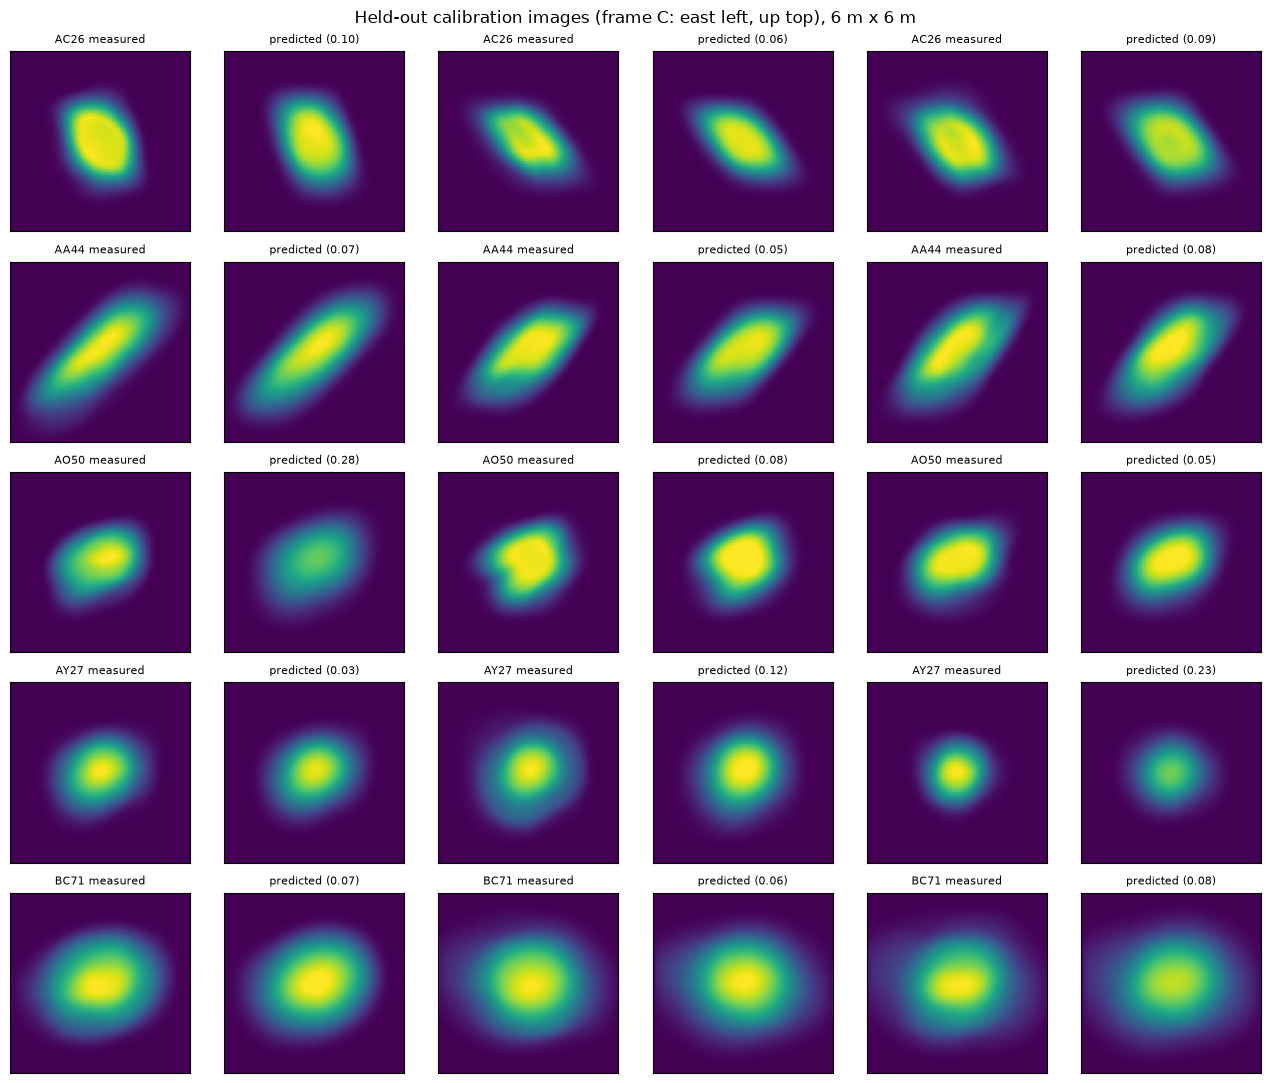

In [4]:
cols = [0, 5, 10]                              # one held-out image per target group
fig, ax = plt.subplots(len(ids), 2 * len(cols), figsize=(13, 2.2 * len(ids)))
for i, h in enumerate(ids):
    for j, k in enumerate(cols):
        vmax = float(meas[i, k].max())
        ax[i, 2 * j].imshow(meas[i, k], vmin=0, vmax=vmax)
        ax[i, 2 * j + 1].imshow(pred[i, k], vmin=0, vmax=vmax)
        ax[i, 2 * j].set_title(f"{h} measured", fontsize=8)
        ax[i, 2 * j + 1].set_title(f"predicted ({err[i, k]:.2f})", fontsize=8)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Held-out calibration images (frame C: east left, up top), 6 m x 6 m")
plt.tight_layout()

## 3. New sun positions and aim points

`build_conditions` turns sun vector, heliostat positions and aim points (tower-base frame) into model
conditions. Positions of the example heliostats are in `heliostat_positions.csv`.

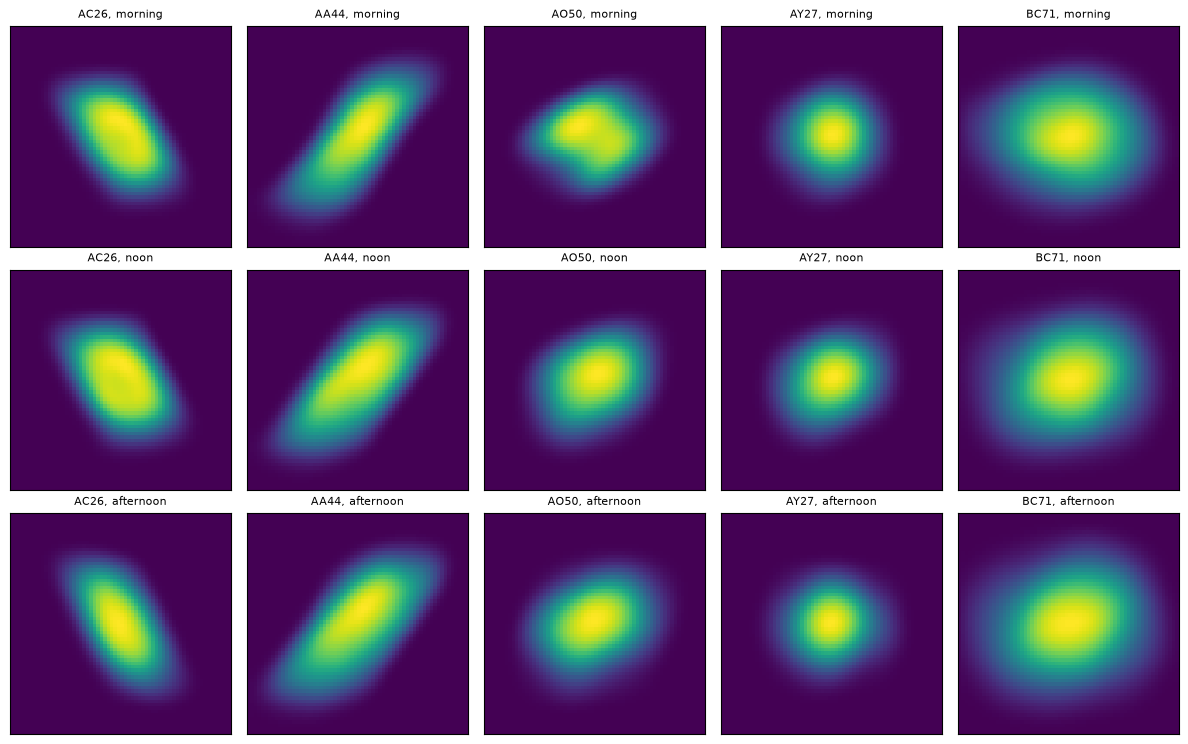

In [5]:
import csv
positions = {r["heliostat_id"]: [float(r[k]) for k in ("x_east_m", "y_north_m", "z_up_m")]
             for r in csv.DictReader(open(DATA / "heliostat_positions.csv"))}
pos = torch.tensor([positions[h] for h in ids])

def sun_vector(azimuth_deg, elevation_deg):
    # unit vector towards the sun; azimuth from north, clockwise
    az, el = math.radians(azimuth_deg), math.radians(elevation_deg)
    return torch.tensor([math.cos(el) * math.sin(az), math.cos(el) * math.cos(az), math.sin(el)])

aim = torch.tensor([[0.0, 0.0, 55.0]]).repeat(len(ids), 1)              # receiver aperture centre
suns = {"morning": sun_vector(110, 25), "noon": sun_vector(180, 60), "afternoon": sun_vector(250, 25)}
fig, ax = plt.subplots(len(suns), len(ids), figsize=(12, 7.5))
for r, (label, sun) in enumerate(suns.items()):
    c, _, _ = build_conditions(sun, pos, aim)                            # [5, 1, 7]
    spots = predictor.predict(ids, c)[:, 0]
    for i, h in enumerate(ids):
        ax[r, i].imshow(spots[i])
        ax[r, i].set_title(f"{h}, {label}", fontsize=8); ax[r, i].set_xticks([]); ax[r, i].set_yticks([])
plt.tight_layout()

## 4. Rays and flux on a plane

`HelioBeamField` combines spot sources and one projection chain: the transformer for heliostats with
context, optionally a fallback (here a Gaussian beam) for the others, the projection CNN for the ray
directions, and the tracking error as broadening. `assignment` tells before any prediction which
heliostat is modelled how.

`from_artifacts()` loads the released encoder cache. `XX01` stands for a heliostat without calibration
data; it gets the Gaussian (`sigma = sqrt(0.58 m^2 + (3.1 mrad * d)^2)`).

In [6]:
field = HelioBeamField.from_artifacts(pointing_accuracy_mrad=1.8, upsampling=4,   # 4 x 4 rays per pixel
                                      fallback=GaussianSource.field_law(sigma_mrad=3.1, sigma0_m=0.58))
all_ids = ids + ["XX01"]
all_pos = torch.cat([pos, torch.tensor([[0.0, 120.0, 1.6]])])
print({k: v for k, v in field.assignment(all_ids).items()})

sun = suns["noon"]
aims = torch.tensor([[-1.5, 0.0, 56.5], [1.5, 0.0, 56.5], [0.0, 0.0, 55.0],
                     [-1.5, 0.0, 53.5], [1.5, 0.0, 53.5], [0.0, 0.0, 56.5]])
powers = torch.full((len(all_ids),), 50e3)                               # W per heliostat
prepared = field.prepare(all_ids, sun, all_pos, aims)                    # once per geometry
rays = field.rays(prepared, aims, powers)                                # [6 * 256^2, 7]: origin, direction, energy
print(tuple(rays.shape), prepared.sources)

{'transformer': ['AC26', 'AA44', 'AO50', 'AY27', 'BC71'], 'gaussian': ['XX01'], 'uncovered': []}


(393216, 7) ['transformer', 'transformer', 'transformer', 'transformer', 'transformer', 'gaussian']


Rays start on the aim plane `y = 0` (one per pixel of the 4x upsampled spot) and run along their
predicted directions. A receiver model
intersects them with its surface (`heliobeamai.receiver`: planar, OVR aperture, cylindrical); here
vertical planes at `y = 0` and 4 m behind it (`y = -4`):

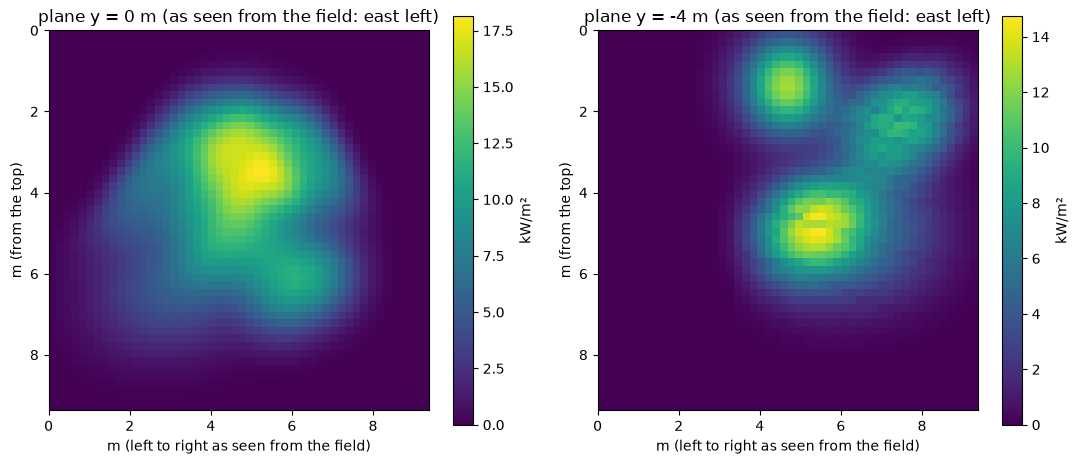

In [7]:
from heliobeamai import PlanarReceiver

# bins of 0.1875 m = 8 x 8 rays, aligned with the ray grid (aim points 0.75 m apart): no aliasing
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, y in zip(ax, (0.0, -4.0)):
    receiver = PlanarReceiver(center=(0.0, y, 55.0), width=9.375, height=9.375, resolution=(50, 50))
    receiver.visualize_flux_distribution(receiver.project_flux(rays), ax=a)   # W/m^2 -> kW/m^2
    a.set_title(f"plane y = {y:g} m (as seen from the field: east left)")
plt.tight_layout()

For optimization loops call `prepare` once per geometry update and `rays` in every iteration: the rays
are differentiable with respect to the aim points.

With DNI, mirror area and reflectivity the powers follow from the cosine effect:
`heliobeamai.predict.receiver_flux(field, receiver, ids, positions, aims, sun, dni, mirror_area, reflectivity)`;
the same from the command line: `heliobeamai predict --help`.

Next: `02_example_data.ipynb` describes all training datasets; `configs/transformer/example.yaml`
trains on the example data (`heliobeamai train-transformer configs/transformer/example.yaml`).